In [1]:
from pathlib import Path
import pickle
import sys

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append("../")

from src.readers.geom_reader import load_geodata
from src.readers.hydro_series import load_metrics_from_directory
from src.timeseries_stats.metrics import evaluate_model
from src.utils.logger import setup_logger

plt.rcParams["font.family"] = "DeJavu Serif"
plt.rcParams["font.serif"] = ["Times New Roman"]

log = setup_logger("chapter_two", log_file="../logs/chapter_two.log")

folder_depth = "../"
log = setup_logger("chapter_two", log_file=f"{folder_depth}/logs/chapter_two.log")
DATA_DIR = Path(f"{folder_depth}/data")
RES_DIR = Path(f"{folder_depth}/res_0426/chapter_two")
FIGURES_DIR = RES_DIR / "figures"
TABLES_DIR = RES_DIR / "tables"
DATA_OUT_DIR = RES_DIR / "data"

# Load watershed geometries and gauge locations
# Load watershed geometries and gauge locations
ws, gauges = load_geodata(folder_depth="../")
common_index = gauges.index.to_list()
basemap_data = gpd.read_file("../data/geometry/basemap_2023.gpkg")

fine_tune_gauges = gpd.read_file("../data/res/FineTuneGauges.gpkg")[
    [
        "gauge_id",
        "name_ru",
        "name_en",
        "geometry",
    ]
]
fine_tune_gauges.set_index("gauge_id", inplace=True)

ft_index = fine_tune_gauges.index.tolist()

rest_gauges = gauges.loc[~gauges.index.isin(ft_index)]
rest_index = rest_gauges.index.tolist()
print(f"Loaded {len(gauges)} gauges with hybrid classification")
ws_nse = gpd.read_file(f"{DATA_DIR}/MODEL_METRICS.geojson")
ws_nse.set_index("gauge_id", inplace=True)

Loaded 996 gauges with hybrid classification


In [2]:
# Base paths for optimization results (GR4J / HBV / RFR metrics JSONs)
BASE_PATHS = {
    "gr4j": Path(f"{DATA_DIR}/optimization/gr4j_simple"),
    "hbv": Path(f"{DATA_DIR}/optimization/hbv_simple"),
    "rfr": Path(f"{DATA_DIR}/optimization/rfr_simple"),
}

# Poor-period simulations (2017–2018) for fine-tune gauges only
POOR_PERIOD_PATH = {
    "gr4j": Path(f"{DATA_DIR}/predictions/gr4j_poor_gauges"),
    "hbv": Path(f"{DATA_DIR}/predictions/hbv_poor_gauges"),
    "rfr": Path(f"{DATA_DIR}/predictions/rfr_poor_gauges"),
    "lstm": Path(f"{DATA_DIR}/predictions/lstm_poor_gauges"),
}

LSTM_PICKLE_PATHS = {
    "gpcp": "../data/lstm_configs/model_runs/cudalstm_q_mm_day_gpcp_no_autocorr_static_1203_080402/test/model_epoch024/test_results.p",
    "e5": "../data/lstm_configs/model_runs/cudalstm_q_mm_day_era5_no_autocorr_static_1203_220232/test/model_epoch020/test_results.p",
    "e5l": "../data/lstm_configs/model_runs/cudalstm_q_mm_day_era5l_no_autocorr_static_1003_133332/test/model_epoch026/test_results.p",
    "mswep": "../data/lstm_configs/model_runs/cudalstm_q_mm_day_mswep_no_autocorr_static_1103_191754/test/model_epoch024/test_results.p",
    "ealstm": "../data/lstm_configs/model_runs/ealstm_q_mm_day_mswep_no_static_0205_144958/test/model_epoch038/test_results.p",
}

NAN_METRICS = {
    "NSE": np.nan,
    "KGE": np.nan,
    "PBIAS": np.nan,
    "RMSE": np.nan,
    "MAE": np.nan,
    "logNSE": np.nan,
    "R2": np.nan,
    "r": np.nan,
    "PFE": np.nan,
}

# --- Main period: conceptual models from optimization directory metrics ---
model_data = {}
for model_name, base_path in BASE_PATHS.items():
    log.info(f"Loading {model_name} results from {base_path}")
    model_data[model_name] = load_metrics_from_directory(base_path)
    log.info(f"  Found {len(model_data[model_name])} gauges")

dataset_dfs = {}

for model_name, model_dict in model_data.items():
    sample_gauge = next(iter(model_dict))
    datasets = list(model_dict[sample_gauge].keys())
    for dataset_name in datasets:
        rows = []
        for gauge_id, gauge_data in model_dict.items():
            if dataset_name in gauge_data:
                m = gauge_data[dataset_name]
                row = {"gauge_id": gauge_id}
                row.update(m)
                rows.append(row)
        df_name = f"{model_name.lower()}_{dataset_name}"
        df = pd.DataFrame(rows).set_index("gauge_id").reindex(common_index)
        dataset_dfs[df_name] = df
        miss = df.isna().all(axis=1).sum()
        print(f"Created {df_name}: {len(df)} gauges × {len(df.columns)} metrics ({miss} missing)")

# --- Main period: LSTM from pickle test_results (same as c2_ChapterTwo) ---
for dataset_name, pickle_path in LSTM_PICKLE_PATHS.items():
    log.info(f"Processing LSTM {dataset_name} from pickle")
    with open(pickle_path, "rb") as f:
        lstm_data = pickle.load(f)
    rows = []
    for gauge_id, gauge_results in lstm_data.items():
        if gauge_id not in common_index:
            continue
        try:
            xr_data = gauge_results["1D"]["xr"]
            obs = np.asarray(xr_data["q_mm_day_obs"], dtype=float).flatten()
            sim = np.asarray(xr_data["q_mm_day_sim"], dtype=float).flatten()
            m = evaluate_model(observed=obs, simulated=sim)
            m["gauge_id"] = gauge_id
            rows.append(m)
        except Exception as e:
            log.warning(f"Error processing gauge {gauge_id} for LSTM {dataset_name}: {e}")
    df_name = f"lstm_{dataset_name}"
    df = pd.DataFrame(rows).set_index("gauge_id").reindex(common_index)
    dataset_dfs[df_name] = df
    miss = df.isna().all(axis=1).sum()
    print(f"Created {df_name}: {len(df)} gauges × {len(df.columns)} metrics ({miss} missing)")

# --- Poor period (2017–2018): CSVs for fine-tune gauges only ---
model_data_poor = {name: {} for name in POOR_PERIOD_PATH}
for model_name, poor_base in POOR_PERIOD_PATH.items():
    for gauge_id in ft_index:
        model_data_poor[model_name][gauge_id] = {}
        for meteo in ["e5", "e5l", "gpcp", "mswep"]:
            try:
                data_df = pd.read_csv(
                    f"{poor_base}/{gauge_id}/{gauge_id}_{meteo}_predictions.csv",
                    index_col="date",
                    parse_dates=True,
                ).loc["2017-01-01":"2018-12-31"]
                metrics = evaluate_model(
                    observed=data_df["q_obs"],
                    simulated=data_df["q_sim"],
                )
            except FileNotFoundError:
                log.debug(f"Poor-period file missing: {model_name} {gauge_id} {meteo}")
                metrics = NAN_METRICS.copy()
            model_data_poor[model_name][gauge_id][meteo] = metrics

dataset_poor_dfs = {}
for model_name, model_dict in model_data_poor.items():
    sample_gauge = next(iter(model_dict))
    datasets = list(model_dict[sample_gauge].keys())
    for dataset_name in datasets:
        rows = []
        for gauge_id, gauge_data in model_dict.items():
            if dataset_name in gauge_data:
                m = gauge_data[dataset_name]
                row = {"gauge_id": gauge_id}
                row.update(m)
                rows.append(row)
        df_name = f"{model_name.lower()}_{dataset_name}"
        df = pd.DataFrame(rows).set_index("gauge_id").reindex(ft_index)
        dataset_poor_dfs[df_name] = df
        miss = df.isna().all(axis=1).sum()
        print(
            f"Created {df_name} (poor period): {len(df)} gauges × {len(df.columns)} metrics ({miss} missing)"
        )

print(f"\nMain dataframes: {len(dataset_dfs)} — {sorted(dataset_dfs.keys())}")
print(f"\nPoor dataframes: {len(dataset_poor_dfs)} — {sorted(dataset_poor_dfs.keys())}")


2026-04-07 01:48:42 | INFO     | PhDLogger | chapter_two | ℹ️  Loading gr4j results from ../data/optimization/gr4j_simple
2026-04-07 01:48:42 | INFO     | PhDLogger | chapter_two | ℹ️    Found 996 gauges
2026-04-07 01:48:42 | INFO     | PhDLogger | chapter_two | ℹ️  Loading hbv results from ../data/optimization/hbv_simple
2026-04-07 01:48:42 | INFO     | PhDLogger | chapter_two | ℹ️    Found 996 gauges
2026-04-07 01:48:42 | INFO     | PhDLogger | chapter_two | ℹ️  Loading rfr results from ../data/optimization/rfr_simple
2026-04-07 01:48:42 | INFO     | PhDLogger | chapter_two | ℹ️    Found 996 gauges
2026-04-07 01:48:42 | INFO     | PhDLogger | chapter_two | ℹ️  Processing LSTM gpcp from pickle


Created gr4j_e5l: 996 gauges × 9 metrics (2 missing)
Created gr4j_gpcp: 996 gauges × 9 metrics (1 missing)
Created gr4j_e5: 996 gauges × 9 metrics (0 missing)
Created gr4j_mswep: 996 gauges × 9 metrics (2 missing)
Created hbv_e5l: 996 gauges × 9 metrics (0 missing)
Created hbv_gpcp: 996 gauges × 9 metrics (0 missing)
Created hbv_e5: 996 gauges × 9 metrics (0 missing)
Created hbv_mswep: 996 gauges × 9 metrics (0 missing)
Created rfr_e5l: 996 gauges × 9 metrics (0 missing)
Created rfr_gpcp: 996 gauges × 9 metrics (0 missing)
Created rfr_e5: 996 gauges × 9 metrics (0 missing)
Created rfr_mswep: 996 gauges × 9 metrics (0 missing)


2026-04-07 01:48:43 | INFO     | PhDLogger | chapter_two | ℹ️  Processing LSTM e5 from pickle


Created lstm_gpcp: 996 gauges × 9 metrics (0 missing)


2026-04-07 01:48:43 | INFO     | PhDLogger | chapter_two | ℹ️  Processing LSTM e5l from pickle


Created lstm_e5: 996 gauges × 9 metrics (0 missing)


2026-04-07 01:48:44 | INFO     | PhDLogger | chapter_two | ℹ️  Processing LSTM mswep from pickle


Created lstm_e5l: 996 gauges × 9 metrics (0 missing)


2026-04-07 01:48:45 | INFO     | PhDLogger | chapter_two | ℹ️  Processing LSTM ealstm from pickle


Created lstm_mswep: 996 gauges × 9 metrics (0 missing)
Created lstm_ealstm: 996 gauges × 9 metrics (0 missing)
Created gr4j_e5 (poor period): 265 gauges × 9 metrics (0 missing)
Created gr4j_e5l (poor period): 265 gauges × 9 metrics (0 missing)
Created gr4j_gpcp (poor period): 265 gauges × 9 metrics (0 missing)
Created gr4j_mswep (poor period): 265 gauges × 9 metrics (0 missing)
Created hbv_e5 (poor period): 265 gauges × 9 metrics (0 missing)
Created hbv_e5l (poor period): 265 gauges × 9 metrics (0 missing)
Created hbv_gpcp (poor period): 265 gauges × 9 metrics (0 missing)
Created hbv_mswep (poor period): 265 gauges × 9 metrics (0 missing)
Created rfr_e5 (poor period): 265 gauges × 9 metrics (0 missing)
Created rfr_e5l (poor period): 265 gauges × 9 metrics (0 missing)
Created rfr_gpcp (poor period): 265 gauges × 9 metrics (0 missing)
Created rfr_mswep (poor period): 265 gauges × 9 metrics (0 missing)
Created lstm_e5 (poor period): 265 gauges × 9 metrics (0 missing)
Created lstm_e5l (poo

In [3]:
# Unblended main metrics live in `dataset_dfs`; poor-period (ft gauges) in `dataset_poor_dfs`.
# `gr4j_*`, `hbv_*`, … below match c2_ChapterTwo: test-period everywhere except ft_index → 2017–2018.


def blend_ft_period(
    main_df: pd.DataFrame, poor_df: pd.DataFrame, ft_ids: list
) -> pd.DataFrame:
    """Fine-tune gauges use poor-period metrics; all others keep main-period metrics."""
    out = main_df.copy()
    ft_ok = [g for g in ft_ids if g in out.index and g in poor_df.index]
    if ft_ok:
        out.loc[ft_ok, :] = poor_df.loc[ft_ok, :]
    return out


gr4j_e5l_poor = dataset_poor_dfs["gr4j_e5l"]
gr4j_gpcp_poor = dataset_poor_dfs["gr4j_gpcp"]
gr4j_e5_poor = dataset_poor_dfs["gr4j_e5"]
gr4j_mswep_poor = dataset_poor_dfs["gr4j_mswep"]

hbv_e5l_poor = dataset_poor_dfs["hbv_e5l"]
hbv_gpcp_poor = dataset_poor_dfs["hbv_gpcp"]
hbv_e5_poor = dataset_poor_dfs["hbv_e5"]
hbv_mswep_poor = dataset_poor_dfs["hbv_mswep"]

rfr_e5l_poor = dataset_poor_dfs["rfr_e5l"]
rfr_gpcp_poor = dataset_poor_dfs["rfr_gpcp"]
rfr_e5_poor = dataset_poor_dfs["rfr_e5"]
rfr_mswep_poor = dataset_poor_dfs["rfr_mswep"]

lstm_e5l_poor = dataset_poor_dfs["lstm_e5l"]
lstm_gpcp_poor = dataset_poor_dfs["lstm_gpcp"]
lstm_e5_poor = dataset_poor_dfs["lstm_e5"]
lstm_mswep_poor = dataset_poor_dfs["lstm_mswep"]

gr4j_e5l = blend_ft_period(dataset_dfs["gr4j_e5l"], gr4j_e5l_poor, ft_index)
gr4j_gpcp = blend_ft_period(dataset_dfs["gr4j_gpcp"], gr4j_gpcp_poor, ft_index)
gr4j_e5 = blend_ft_period(dataset_dfs["gr4j_e5"], gr4j_e5_poor, ft_index)
gr4j_mswep = blend_ft_period(dataset_dfs["gr4j_mswep"], gr4j_mswep_poor, ft_index)

hbv_e5l = blend_ft_period(dataset_dfs["hbv_e5l"], hbv_e5l_poor, ft_index)
hbv_gpcp = blend_ft_period(dataset_dfs["hbv_gpcp"], hbv_gpcp_poor, ft_index)
hbv_e5 = blend_ft_period(dataset_dfs["hbv_e5"], hbv_e5_poor, ft_index)
hbv_mswep = blend_ft_period(dataset_dfs["hbv_mswep"], hbv_mswep_poor, ft_index)

rfr_e5l = blend_ft_period(dataset_dfs["rfr_e5l"], rfr_e5l_poor, ft_index)
rfr_gpcp = blend_ft_period(dataset_dfs["rfr_gpcp"], rfr_gpcp_poor, ft_index)
rfr_e5 = blend_ft_period(dataset_dfs["rfr_e5"], rfr_e5_poor, ft_index)
rfr_mswep = blend_ft_period(dataset_dfs["rfr_mswep"], rfr_mswep_poor, ft_index)

lstm_e5l = blend_ft_period(dataset_dfs["lstm_e5l"], lstm_e5l_poor, ft_index)
lstm_gpcp = blend_ft_period(dataset_dfs["lstm_gpcp"], lstm_gpcp_poor, ft_index)
lstm_e5 = blend_ft_period(dataset_dfs["lstm_e5"], lstm_e5_poor, ft_index)
lstm_mswep = blend_ft_period(dataset_dfs["lstm_mswep"], lstm_mswep_poor, ft_index)

# EA-LSTM (MSWEP only): no separate poor-period run in CSV layout — keep pickle metrics for all gauges
ealstm_mswep = dataset_dfs["lstm_ealstm"]

print("✓ Blended model×source dataframes (ft_index → poor period 2017–2018)")
print("  GR4J: gr4j_e5l, gr4j_gpcp, gr4j_e5, gr4j_mswep")
print("  HBV:  hbv_e5l, hbv_gpcp, hbv_e5, hbv_mswep")
print("  RFR:  rfr_e5l, rfr_gpcp, rfr_e5, rfr_mswep")
print("  LSTM: lstm_e5l, lstm_gpcp, lstm_e5, lstm_mswep")
print("  EA-LSTM MSWEP (unblended): ealstm_mswep")


✓ Blended model×source dataframes (ft_index → poor period 2017–2018)
  GR4J: gr4j_e5l, gr4j_gpcp, gr4j_e5, gr4j_mswep
  HBV:  hbv_e5l, hbv_gpcp, hbv_e5, hbv_mswep
  RFR:  rfr_e5l, rfr_gpcp, rfr_e5, rfr_mswep
  LSTM: lstm_e5l, lstm_gpcp, lstm_e5, lstm_mswep
  EA-LSTM MSWEP (unblended): ealstm_mswep


**Note:** Model metrics are loaded in cells 1–2 only (optimization JSON + LSTM pickles for the main period; 2017–2018 CSV predictions for fine-tune gauges; blended into `hbv_e5l`, …).


In [4]:
def get_quality_category(value: float, metric_type: str) -> str:
    """Map metric score to quality category using standard thresholds.

    Args:
        value: Metric value
        metric_type: One of 'NSE', 'R2', or 'PBIAS'

    Returns:
        Quality category: 'Отл.', 'Хор.', 'Удов.', or 'Плох.'

    Example:
        >>> get_quality_category(0.85, "NSE")
        'Отл.'
        >>> get_quality_category(12.0, "PBIAS")
        'Хор.'
    """
    if pd.isna(value):
        return "Плох."

    if metric_type == "R2":
        if value > 0.85:
            return "Отл."
        elif value > 0.70:
            return "Хор."
        elif value > 0.50:
            return "Удов."
        else:
            return "Плох."

    elif metric_type == "NSE":
        if value > 0.80:
            return "Отл."
        elif value > 0.70:
            return "Хор."
        elif value > 0.50:
            return "Удов."
        else:
            return "Плох."

    elif metric_type == "PBIAS":
        abs_value = abs(value)
        if abs_value <= 10:
            return "Отл."
        elif abs_value <= 15:
            return "Хор."
        elif abs_value <= 35:
            return "Удов."
        else:
            return "Плох."

    else:
        raise ValueError(
            f"Unknown metric_type: {metric_type}. Must be 'R2', 'NSE', or 'PBIAS'"
        )


def calculate_composite_score(nse: float, r2: float, pbias: float) -> tuple[float, str]:
    """Calculate composite quality score from NSE, R2, and PBIAS.

    This function implements a multi-criteria evaluation:
    1. Classify each metric individually (Poor/Satisfactory/Good/Great)
    2. Encode to numeric scale (1/2/3/4)
    3. Average the three scores
    4. Decode back to categorical grade

    Args:
        nse: Nash-Sutcliffe Efficiency
        r2: Coefficient of Determination
        pbias: Percent Bias

    Returns:
        Tuple of (numeric_score, categorical_grade) where:
        - numeric_score: 1.0-4.0 (higher is better)
        - categorical_grade: 'Плох.', 'Удов.', 'Хор.', or 'Отл.'

    Example:
        >>> calculate_composite_score(0.85, 0.80, 12.0)
        (3.33, 'Хор.')
    """
    # Handle missing values
    if pd.isna(nse) or pd.isna(r2) or pd.isna(pbias):
        return 0.0, "Плох."

    # Step 1: Classify individual metrics
    nse_category = get_quality_category(nse, "NSE")
    r2_category = get_quality_category(r2, "R2")
    pbias_category = get_quality_category(pbias, "PBIAS")

    # Step 2: Encode to numeric scores (0-based: 0=Плох., 1=Удов., 2=Хор., 3=Отл.)
    category_to_score = {"Плох.": 0, "Удов.": 1, "Хор.": 2, "Отл.": 3}

    nse_score = category_to_score[nse_category]
    r2_score = category_to_score[r2_category]
    pbias_score = category_to_score[pbias_category]

    # Step 3: Aggregate scores (equal weighting)
    composite_numeric = (nse_score + r2_score + pbias_score) / 3.0

    # Step 4: Decode to categorical label
    if composite_numeric < 0.5:
        composite_category = "Плох."
    elif composite_numeric < 1.5:
        composite_category = "Удов."
    elif composite_numeric < 2.5:
        composite_category = "Хор."
    else:
        composite_category = "Отл."

    return composite_numeric, composite_category


# Display helper function documentation
print("\n" + "=" * 80)
print("HELPER FUNCTIONS DEFINED")
print("=" * 80)
print("  - get_quality_category(value, metric_type)")
print("  - calculate_composite_score(nse, r2, pbias)")
print("\nThresholds:")
print("  R²:    Отл. (>0.85) | Хор. (0.70-0.85) | Удов. (0.50-0.70) | Плох. (≤0.50)")
print("  NSE:   Отл. (>0.80) | Хор. (0.70-0.80) | Удов. (0.50-0.70) | Плох. (≤0.50)")
print("  PBIAS: Отл. (≤±10%) | Хор. (±10-±15%) | Удов. (±15-±35%) | Плох. (>±35%)")



HELPER FUNCTIONS DEFINED
  - get_quality_category(value, metric_type)
  - calculate_composite_score(nse, r2, pbias)

Thresholds:
  R²:    Отл. (>0.85) | Хор. (0.70-0.85) | Удов. (0.50-0.70) | Плох. (≤0.50)
  NSE:   Отл. (>0.80) | Хор. (0.70-0.80) | Удов. (0.50-0.70) | Плох. (≤0.50)
  PBIAS: Отл. (≤±10%) | Хор. (±10-±15%) | Удов. (±15-±35%) | Плох. (>±35%)


### NSE vs AREA

/tmp/ipykernel_2040292/3933536210.py:15: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_d = cm.get_cmap("RdYlGn", len(NSE_LIMITS) - 1)


без коррекции: n=996, NSE<-1: 3
с коррекцией:  n=996, NSE<-1: 9


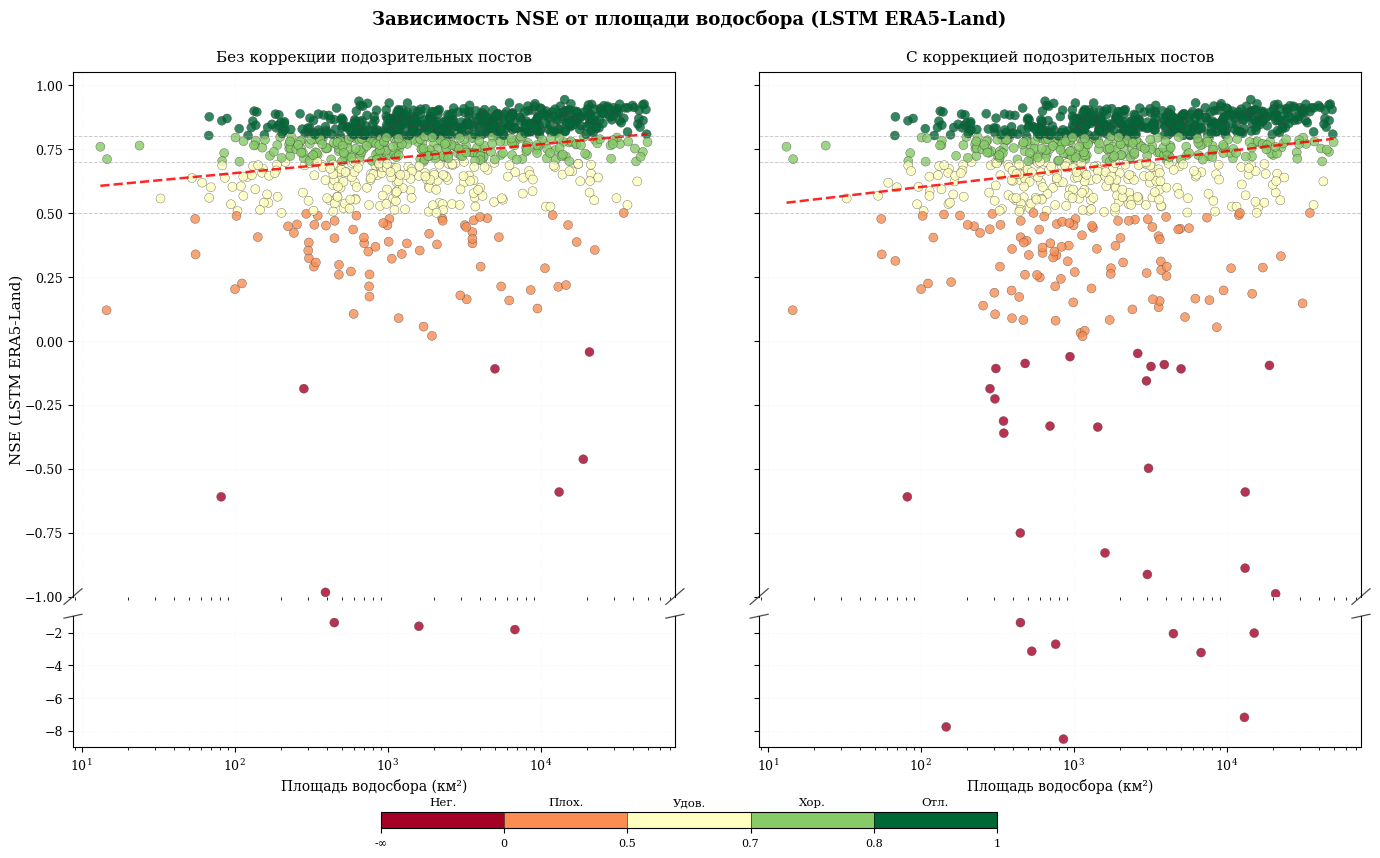

2026-04-07 03:26:40 | INFO     | PhDLogger | chapter_two | ℹ️  NSE vs area: 4:1 split, top panel dominant


In [ ]:
# NSE vs catchment area: без / с коррекцией подозрительных постов
# Верх [-1, 1] — крупно; низ [min, -1] — компактная полоса для экстремумов

import matplotlib as mpl
from matplotlib import cm
from matplotlib.lines import Line2D

SPLIT = -1.0
Y_TOP = 1.05

NSE_LIMITS = [-np.inf, 0.0, 0.5, 0.7, 0.8, 1.0]
NSE_FINITE = [-1e10, 0.0, 0.5, 0.7, 0.8, 1.0]
CB_LABELS = ["\u041d\u0435\u0433.", "\u041f\u043b\u043e\u0445.", "\u0423\u0434\u043e\u0432.", "\u0425\u043e\u0440.", "\u041e\u0442\u043b."]

cmap_d = cm.get_cmap("RdYlGn", len(NSE_LIMITS) - 1)
norm_d = mpl.colors.BoundaryNorm(NSE_FINITE, cmap_d.N)


def _collect(series):
    idx = series.dropna().index
    ok = idx[idx.isin(ws.index)]
    return pd.DataFrame({"area": ws.loc[ok, "area_km2"].astype(float).values,
                         "nse": series.loc[ok].astype(float).values}, index=ok)


df_no = _collect(dataset_dfs["lstm_e5l"]["NSE"])
df_yes = _collect(lstm_e5l["NSE"])

y_bot = min(df_no["nse"].min(), df_yes["nse"].min())
y_bot = (y_bot - 0.5) if y_bot < SPLIT else (SPLIT - 1)


def _trend(df):
    s = df[np.isfinite(df["nse"]) & (df["nse"] >= -2)].copy()
    if len(s) < 3:
        return None
    lx = np.log10(s["area"].to_numpy())
    y = s["nse"].to_numpy()
    r = float(np.corrcoef(lx, y)[0, 1])
    z = np.polyfit(lx, y, 1)
    p = np.poly1d(z)
    xl = np.logspace(np.log10(s["area"].min()), np.log10(s["area"].max()), 200)
    return xl, p(np.log10(xl)), r


def _draw(ax_t, ax_b, df, title):
    top = df[df["nse"] >= SPLIT]
    bot = df[df["nse"] < SPLIT]

    for ax in (ax_t, ax_b):
        ax.set_xscale("log")

    kw = dict(cmap=cmap_d, norm=norm_d, edgecolors="0.25", linewidths=0.3, alpha=0.8, s=42)
    if not top.empty:
        ax_t.scatter(top["area"], top["nse"], c=top["nse"], **kw)
    if not bot.empty:
        ax_b.scatter(bot["area"], bot["nse"], c=bot["nse"], **kw)

    tr = _trend(df)
    legs_h, legs_l = [], []
    if tr:
        xl, yl, r = tr
        m_t = yl >= SPLIT
        m_b = yl < SPLIT
        if m_t.any():
            ax_t.plot(xl[m_t], yl[m_t], "r--", lw=1.8, alpha=0.85)
        if m_b.any():
            ax_b.plot(xl[m_b], yl[m_b], "r--", lw=1.8, alpha=0.85)
        legs_h.append(Line2D([0], [0], color="r", ls="--", lw=1.8))
        legs_l.append(f"R = {r:.3f}")

    n_ext = len(bot)
    if n_ext:
        legs_h.append(Line2D([0], [0], marker="o", ls="none", color="none",
                             markerfacecolor=cmap_d(0), markeredgecolor="0.25", ms=7))
        legs_l.append(f"NSE < {SPLIT:g}  (n = {n_ext})")

    for thr in (0.5, 0.7, 0.8):
        ax_t.axhline(thr, color="0.6", ls="--", lw=0.7, alpha=0.5)

    ax_t.set_ylim(SPLIT, Y_TOP)
    ax_b.set_ylim(y_bot, SPLIT)

    ax_t.spines["bottom"].set_visible(False)
    ax_b.spines["top"].set_visible(False)
    ax_t.tick_params(bottom=False, labelbottom=False)

    d = 0.015
    bkw = dict(color="0.3", clip_on=False, lw=0.9)
    ax_t.plot((-d, d), (-d, d), transform=ax_t.transAxes, **bkw)
    ax_t.plot((1 - d, 1 + d), (-d, d), transform=ax_t.transAxes, **bkw)
    ax_b.plot((-d, d), (1 - d, 1 + d), transform=ax_b.transAxes, **bkw)
    ax_b.plot((1 - d, 1 + d), (1 - d, 1 + d), transform=ax_b.transAxes, **bkw)

    ax_t.set_title(title, fontsize=11, pad=8)
    ax_b.set_xlabel("\u041f\u043b\u043e\u0449\u0430\u0434\u044c \u0432\u043e\u0434\u043e\u0441\u0431\u043e\u0440\u0430 (\u043a\u043c\u00b2)", fontsize=10)

    for ax in (ax_t, ax_b):
        ax.grid(True, alpha=0.2, ls=":", lw=0.4)
        ax.tick_params(labelsize=9)

    if legs_h:
        ax_t.legend(legs_h, legs_l, loc="lower right", fontsize=8,
                    framealpha=0.9, edgecolor="0.7", borderpad=0.5)


fig = plt.figure(figsize=(14, 9))

gs = fig.add_gridspec(
    2, 2,
    height_ratios=[4, 1],
    hspace=0.06, wspace=0.14,
    left=0.06, right=0.98, top=0.88, bottom=0.13,
)

ax0_t = fig.add_subplot(gs[0, 0])
ax0_b = fig.add_subplot(gs[1, 0], sharex=ax0_t)
ax1_t = fig.add_subplot(gs[0, 1])
ax1_b = fig.add_subplot(gs[1, 1], sharex=ax1_t)

_draw(ax0_t, ax0_b, df_no,
      "Без коррекции подозрительных постов")
_draw(ax1_t, ax1_b, df_yes,
      "С коррекцией подозрительных постов")

fig.text(0.015, 0.55, "NSE (LSTM ERA5-Land)", va="center", rotation=90, fontsize=11)
ax1_t.tick_params(labelleft=False)
ax1_b.tick_params(labelleft=False)

fig.suptitle(
    "\u0417\u0430\u0432\u0438\u0441\u0438\u043c\u043e\u0441\u0442\u044c NSE \u043e\u0442 \u043f\u043b\u043e\u0449\u0430\u0434\u0438 \u0432\u043e\u0434\u043e\u0441\u0431\u043e\u0440\u0430 (LSTM ERA5-Land)",
    fontsize=13, fontweight="bold", y=0.95,
)

cax = fig.add_axes([0.28, 0.04, 0.44, 0.018])
sm = cm.ScalarMappable(norm=norm_d, cmap=cmap_d)
sm.set_array([])
cb = fig.colorbar(sm, cax=cax, orientation="horizontal", drawedges=True)
cb.ax.tick_params(labelsize=8)
ticks = cb.get_ticks()
cb.ax.set_xticklabels(
    [("-\u221e" if t < -1e9 else ("\u221e" if t > 1e9 else (str(int(t)) if t == int(t) else f"{t:g}")))
     for t in ticks]
)
for i, txt in enumerate(CB_LABELS):
    cb.ax.text(
        (i + 0.5) / len(CB_LABELS), 1.3, txt,
        transform=cb.ax.transAxes, ha="center", va="bottom",
        fontsize=8.5, clip_on=False,
    )

print(f"\u0431\u0435\u0437 \u043a\u043e\u0440\u0440\u0435\u043a\u0446\u0438\u0438: n={len(df_no)}, NSE<{SPLIT:g}: {(df_no['nse']<SPLIT).sum()}")
print(f"\u0441 \u043a\u043e\u0440\u0440\u0435\u043a\u0446\u0438\u0435\u0439:  n={len(df_yes)}, NSE<{SPLIT:g}: {(df_yes['nse']<SPLIT).sum()}")
plt.show()
log.info("NSE vs area: 4:1 split, top panel dominant")

In [6]:
# ============================================================================
# STEP 1: CALCULATE COMPOSITE SCORES FOR ALL COMBINATIONS
# ============================================================================

# Define all model/source dataframe combinations
all_combinations = {
    "GR4J_ERA5-Land": gr4j_e5l,
    "GR4J_GPCP": gr4j_gpcp,
    "GR4J_ERA5": gr4j_e5,
    "GR4J_MSWEP": gr4j_mswep,
    "HBV_ERA5-Land": hbv_e5l,
    "HBV_GPCP": hbv_gpcp,
    "HBV_ERA5": hbv_e5,
    "HBV_MSWEP": hbv_mswep,
    "RFR_ERA5-Land": rfr_e5l,
    "RFR_GPCP": rfr_gpcp,
    "RFR_ERA5": rfr_e5,
    "RFR_MSWEP": rfr_mswep,
    "LSTM_ERA5-Land": lstm_e5l,
    "LSTM_GPCP": lstm_gpcp,
    "LSTM_ERA5": lstm_e5,
    "LSTM_MSWEP": lstm_mswep,
}

log.info(
    f"Calculating composite scores for {len(all_combinations)} model/source combinations"
)

# Create composite scores for all combinations
composite_results = {}

for combo_name, df in all_combinations.items():
    scores = []
    grades = []

    for gauge_id in df.index:
        nse = df.loc[gauge_id, "NSE"]
        r2 = df.loc[gauge_id, "R2"]
        pbias = df.loc[gauge_id, "PBIAS"]

        score, grade = calculate_composite_score(nse, r2, pbias)
        scores.append(score)
        grades.append(grade)

    composite_results[f"Composite_Score_{combo_name}"] = pd.Series(scores, index=df.index)
    composite_results[f"Overall_Grade_{combo_name}"] = pd.Series(grades, index=df.index)

# Create combined dataframe with all composite results
composite_df = pd.DataFrame(composite_results, index=common_index)

log.info(f"Composite scores calculated: {composite_df.shape}")

# Display summary statistics
print("\n" + "=" * 80)
print("COMPOSITE SCORING SUMMARY")
print("=" * 80)

summary_data = []
for combo_name in all_combinations.keys():
    score_col = f"Composite_Score_{combo_name}"
    grade_col = f"Overall_Grade_{combo_name}"

    scores = composite_df[score_col]
    grades = composite_df[grade_col]

    summary_data.append(
        {
            "Model/Source": combo_name,
            "Mean Score": scores.mean(),
            "Median Score": scores.median(),
            "Отл. (%)": (grades == "Отл.").sum() / len(grades) * 100,
            "Хор. (%)": (grades == "Хор.").sum() / len(grades) * 100,
            "Удов. (%)": (grades == "Удов.").sum() / len(grades) * 100,
            "Плох. (%)": (grades == "Плох.").sum() / len(grades) * 100,
        }
    )

summary_table = pd.DataFrame(summary_data)
print("\nTop 10 Performers by Mean Score:")
print(
    summary_table.sort_values("Mean Score", ascending=False)
    .head(10)
    .to_string(index=False)
)

print("\n✓ Composite scoring complete")


2026-04-07 01:48:54 | INFO     | PhDLogger | chapter_two | ℹ️  Calculating composite scores for 16 model/source combinations
2026-04-07 01:48:54 | INFO     | PhDLogger | chapter_two | ℹ️  Composite scores calculated: (996, 32)



COMPOSITE SCORING SUMMARY

Top 10 Performers by Mean Score:
  Model/Source  Mean Score  Median Score  Отл. (%)  Хор. (%)  Удов. (%)  Плох. (%)
LSTM_ERA5-Land    2.024096      2.333333 33.734940 41.967871  19.277108   5.020080
    LSTM_MSWEP    1.970549      2.166667 30.321285 41.867470  21.887550   5.923695
     LSTM_ERA5    1.957831      2.000000 29.116466 44.076305  21.485944   5.321285
     LSTM_GPCP    1.884873      2.000000 23.995984 46.285141  23.594378   6.124498
 HBV_ERA5-Land    1.500335      1.666667 12.851406 37.650602  35.943775  13.554217
     RFR_MSWEP    1.489290      1.333333  9.839357 39.859438  40.160643  10.140562
GR4J_ERA5-Land    1.482932      1.333333 14.156627 33.634538  37.951807  14.257028
 RFR_ERA5-Land    1.463521      1.333333  9.839357 39.056225  38.453815  12.650602
      RFR_ERA5    1.460509      1.333333  9.337349 38.955823  39.156627  12.550201
      RFR_GPCP    1.426372      1.333333  8.232932 38.152610  41.566265  12.048193

✓ Composite scoring compl

In [7]:
# ============================================================================
# STEP 2: IDENTIFY BEST MODEL/SOURCE COMBINATION PER GAUGE
# ============================================================================

score_cols = [col for col in composite_df.columns if col.startswith("Composite_Score_")]
grade_cols = [col for col in composite_df.columns if col.startswith("Overall_Grade_")]

# Create mapping from score column to readable model/source name
score_to_name = {
    col: col.replace("Composite_Score_", "").replace("_", " (") + ")"
    for col in score_cols
}

log.info(f"Identifying best model/source for {len(composite_df)} gauges")

# Initialize results
best_model_names = []
best_composite_scores = []
best_composite_grades = []
best_model_types = []  # Track model type (GR4J, HBV, RFR, LSTM)
best_sources = []  # Track precipitation source

for gauge_id in composite_df.index:
    gauge_scores = composite_df.loc[gauge_id, score_cols]
    max_score = gauge_scores.max()

    # Handle ties by selecting model with highest NSE
    max_score_cols = gauge_scores[gauge_scores == max_score].index.tolist()

    if len(max_score_cols) == 1:
        best_col = max_score_cols[0]
    else:
        # TIE-BREAKER: Use NSE
        tie_nse_values = {}
        for col in max_score_cols:
            combo_name = col.replace("Composite_Score_", "")
            df = all_combinations[combo_name]
            tie_nse_values[col] = df.loc[gauge_id, "NSE"]
        best_col = max(tie_nse_values, key=tie_nse_values.get)

    # Get corresponding grade
    grade_col = best_col.replace("Composite_Score_", "Overall_Grade_")
    best_grade = composite_df.loc[gauge_id, grade_col]

    # Extract model type and source
    combo_name = best_col.replace("Composite_Score_", "")
    model_type, source = combo_name.split("_", 1)

    # Store results
    best_model_names.append(score_to_name[best_col])
    best_composite_scores.append(max_score)
    best_composite_grades.append(best_grade)
    best_model_types.append(model_type)
    best_sources.append(source)

# Create series with results
best_overall_df = pd.DataFrame(
    {
        "Best_Model_Name": best_model_names,
        "Best_Model_Type": best_model_types,
        "Best_Source": best_sources,
        "Composite_Score": best_composite_scores,
        "Overall_Grade": best_composite_grades,
    },
    index=composite_df.index,
)

# Add to composite dataframe
composite_df = pd.concat([composite_df, best_overall_df], axis=1)

# Display summary
print("\n" + "=" * 80)
print("BEST MODEL IDENTIFICATION SUMMARY")
print("=" * 80)

print("\nBest Model Type Distribution:")
model_type_counts = best_overall_df["Best_Model_Type"].value_counts()
for model_type, count in model_type_counts.items():
    pct = (count / len(best_overall_df)) * 100
    mean_score = best_overall_df[best_overall_df["Best_Model_Type"] == model_type][
        "Composite_Score"
    ].mean()
    print(
        f"  {model_type:6s}: {count:3d} gauges ({pct:5.1f}%) | Mean Score: {mean_score:.2f}"
    )

print("\nBest Precipitation Source Distribution:")
source_counts = best_overall_df["Best_Source"].value_counts()
for source, count in source_counts.items():
    pct = (count / len(best_overall_df)) * 100
    print(f"  {source:12s}: {count:3d} gauges ({pct:5.1f}%)")

print("\nOverall Grade Distribution:")
grade_counts = best_overall_df["Overall_Grade"].value_counts()
for grade in ["Отл.", "Хор.", "Удов.", "Плох."]:
    count = grade_counts.get(grade, 0)
    pct = (count / len(best_overall_df)) * 100
    print(f"  {grade:12s}: {count:3d} ({pct:5.1f}%)")

print("\nComposite Score Statistics:")
print(f"  Mean:   {best_overall_df['Composite_Score'].mean():.2f}")
print(f"  Median: {best_overall_df['Composite_Score'].median():.2f}")
print(
    f"  Range:  [{best_overall_df['Composite_Score'].min():.2f}, {best_overall_df['Composite_Score'].max():.2f}]"
)

print("\n✓ Best model identification complete")


2026-04-07 01:48:54 | INFO     | PhDLogger | chapter_two | ℹ️  Identifying best model/source for 996 gauges



BEST MODEL IDENTIFICATION SUMMARY

Best Model Type Distribution:
  LSTM  : 652 gauges ( 65.5%) | Mean Score: 2.46
  GR4J  : 127 gauges ( 12.8%) | Mean Score: 2.48
  HBV   : 125 gauges ( 12.6%) | Mean Score: 2.37
  RFR   :  92 gauges (  9.2%) | Mean Score: 2.24

Best Precipitation Source Distribution:
  ERA5-Land   : 319 gauges ( 32.0%)
  MSWEP       : 288 gauges ( 28.9%)
  ERA5        : 249 gauges ( 25.0%)
  GPCP        : 140 gauges ( 14.1%)

Overall Grade Distribution:
  Отл.        : 526 ( 52.8%)
  Хор.        : 395 ( 39.7%)
  Удов.       :  75 (  7.5%)
  Плох.       :   0 (  0.0%)

Composite Score Statistics:
  Mean:   2.43
  Median: 2.67
  Range:  [0.67, 3.00]

✓ Best model identification complete


In [8]:
# ============================================================================
# STEP 3: MERGE WITH HYBRID CLUSTER ASSIGNMENTS
# ============================================================================

# Hybrid class labels: exported by c1_2_HybridClustering → gauge_hybrid_mapping.csv
_hybrid_csv = Path(folder_depth) / "res_0426/chapter_one/tables/gauge_hybrid_mapping.csv"
if _hybrid_csv.is_file():
    gauge_mapping = pd.read_csv(_hybrid_csv, index_col="gauge_id")
elif "hybrid_class" in gauges.columns:
    gauge_mapping = gauges[["hybrid_class"]].copy()
else:
    raise FileNotFoundError(
        f"{_hybrid_csv} not found and gauges has no hybrid_class column. "
        "Run notebooks/c1_2_HybridClustering.ipynb to export the mapping."
    )
gauge_mapping.index = gauge_mapping.index.astype(str)

# Merge best performance with hybrid cluster assignments
performance_with_clusters = composite_df.copy()
_perf_ix = performance_with_clusters.index.astype(str)
performance_with_clusters["hybrid_class"] = (
    gauge_mapping["hybrid_class"].reindex(_perf_ix).to_numpy()
)

# Remove gauges without cluster assignment
performance_with_clusters = performance_with_clusters.dropna(subset=["hybrid_class"])

log.info(
    f"Merged performance with {performance_with_clusters['hybrid_class'].nunique()} hybrid clusters"
)

# ============================================================================
# STEP 4: CREATE SUMMARY MATRIX (Hybrid Class × Model Type)
# ============================================================================

# For each model type, calculate average composite score per cluster
model_types = ["GR4J", "HBV", "RFR", "LSTM"]
cluster_performance = {}

for model_type in model_types:
    # Get all score columns for this model
    model_score_cols = [
        col for col in score_cols if col.startswith(f"Composite_Score_{model_type}_")
    ]

    # For each gauge, get the best score across sources for this model
    best_model_scores = performance_with_clusters[model_score_cols].max(axis=1)

    # Calculate mean score per cluster
    cluster_means = best_model_scores.groupby(
        performance_with_clusters["hybrid_class"]
    ).mean()

    cluster_performance[model_type] = cluster_means

# Create summary matrix: Rows = Clusters, Columns = Models
summary_matrix = pd.DataFrame(cluster_performance)
summary_matrix = summary_matrix.sort_index()

# Calculate cluster statistics
cluster_stats = pd.DataFrame(
    {
        "Best_Model": summary_matrix.idxmax(axis=1),
        "Best_Score": summary_matrix.max(axis=1),
        "Worst_Score": summary_matrix.min(axis=1),
        "Score_Range": summary_matrix.max(axis=1) - summary_matrix.min(axis=1),
        "N_Gauges": performance_with_clusters.groupby("hybrid_class").size(),
    }
)

# Display results
print("\n" + "=" * 80)
print("HYBRID CLUSTER ANALYSIS: Model Performance by Geo-Hydro Class")
print("=" * 80)

print("\nAverage Composite Score by Cluster and Model:")
print(summary_matrix.round(2).to_string())

print("\n\nCluster Summary Statistics:")
print(cluster_stats.round(2).to_string())

# Identify clusters where model choice matters most
print("\n\nClusters with Highest Model Sensitivity (Score Range > 0.5):")
sensitive_clusters = cluster_stats[cluster_stats["Score_Range"] > 0.5].sort_values(
    "Score_Range", ascending=False
)
if len(sensitive_clusters) > 0:
    print(sensitive_clusters.round(2).to_string())
else:
    print("  None (all clusters have Score Range ≤ 0.5)")

# Identify best-performing clusters
print("\n\nTop 5 Best-Performing Clusters (Highest Best Score):")
top_clusters = cluster_stats.nlargest(5, "Best_Score")
print(top_clusters.round(2).to_string())

print("\n✓ Hybrid cluster analysis complete")

2026-04-07 01:48:55 | INFO     | PhDLogger | chapter_two | ℹ️  Merged performance with 20 hybrid clusters



HYBRID CLUSTER ANALYSIS: Model Performance by Geo-Hydro Class

Average Composite Score by Cluster and Model:
               GR4J   HBV   RFR  LSTM
hybrid_class                         
Ф1-Г1          1.38  1.52  1.22  1.90
Ф1-Г3          1.32  1.37  1.13  1.63
Ф1-Г5          1.27  1.38  1.41  1.84
Ф1-Смешанный   0.94  0.92  0.96  1.44
Ф10-Г1         2.22  2.42  1.64  2.67
Ф10-Г3         1.72  1.87  1.60  2.32
Ф10-Смешанный  1.72  1.83  1.65  2.37
Ф2-Смешанный   1.48  1.49  1.25  1.81
Ф3-Г4          1.40  1.31  1.81  2.13
Ф4-Г8          1.83  1.97  1.85  2.42
Ф4-Смешанный   2.35  2.24  2.24  2.79
Ф5-Г2          1.86  2.10  1.60  2.42
Ф5-Смешанный   1.57  1.90  1.20  2.33
Ф6-Смешанный   1.48  1.68  1.65  2.52
Ф7-Г1          2.12  1.94  1.81  2.41
Ф7-Смешанный   1.83  1.86  1.53  2.38
Ф8-Смешанный   1.78  1.93  1.65  2.41
Ф9-Г7          1.32  1.38  1.41  2.35
Ф9-Г9          1.67  1.67  1.65  2.47
Ф9-Смешанный   2.13  2.03  1.89  2.55


Cluster Summary Statistics:
              Best_Model

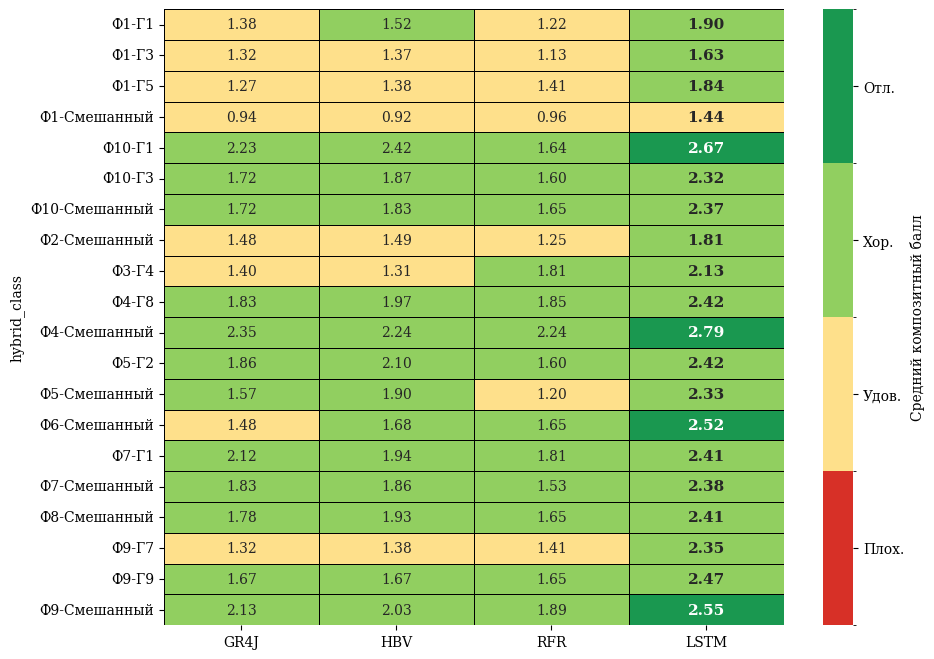

In [9]:
# ============================================================================
# VISUALIZATION 1: Heatmap of Cluster Performance Matrix
# ============================================================================

import matplotlib.colors as mcolors
import seaborn as sns

fig, ax = plt.subplots(figsize=(10, 8))

# Define discrete colormap for heatmap (0-based scale)
heatmap_colors = ["#d73027", "#fee08b", "#91cf60", "#1a9850"]
heatmap_boundaries = [0.0, 0.5, 1.5, 2.5, 3.0]
heatmap_cmap = mcolors.ListedColormap(heatmap_colors)
heatmap_norm = mcolors.BoundaryNorm(heatmap_boundaries, len(heatmap_colors))

# Create heatmap with annotated values
sns.heatmap(
    summary_matrix,
    annot=True,
    fmt=".2f",
    cmap=heatmap_cmap,
    norm=heatmap_norm,
    cbar_kws={
        "label": "Средний композитный балл",
        "ticks": [0.25, 1.0, 2.0, 2.75],
        "format": lambda x, pos: ["Плох.", "Удов.", "Хор.", "Отл."][
            0 if x < 0.5 else 1 if x < 1.5 else 2 if x < 2.5 else 3
        ],
    },
    ax=ax,
    linewidths=0.5,
    linecolor="black",
)

# Make text bold for best model in each cluster
for row_idx, cluster_name in enumerate(summary_matrix.index):
    best_model = cluster_stats.loc[cluster_name, "Best_Model"]
    col_idx = summary_matrix.columns.get_loc(best_model)

    # Find and make the corresponding text annotation bold
    for text in ax.texts:
        # Get text position (center of cell)
        text_x, text_y = text.get_position()
        # Check if this text is in the best model cell
        if abs(text_x - (col_idx + 0.5)) < 0.1 and abs(text_y - (row_idx + 0.5)) < 0.1:
            text.set_weight("bold")
            text.set_fontsize(11)
            break

In [10]:
# ============================================================================
# STEP 5: PREPARE SPATIAL DATA FOR VISUALIZATION
# ============================================================================

import matplotlib.colors as mcolors

from src.plots.hex_maps import hexes_plots_n

# Merge composite scores into spatial dataframe
ws_composite = ws.copy()

# Add best model performance metrics for each model type
for model_type in model_types:
    # Get all score columns for this model
    model_score_cols = [
        col
        for col in composite_df.columns
        if col.startswith(f"Composite_Score_{model_type}_")
    ]

    # Get best score across sources for this model
    best_scores = composite_df[model_score_cols].max(axis=1)
    # FIX: Fill NaN values with 0 to ensure complete hex coverage
    best_scores = best_scores.fillna(0.0)
    ws_composite[f"Best_{model_type}_Score"] = best_scores.loc[ws_composite.index].values

# Add overall best performance
ws_composite["Best_Overall_Score"] = (
    composite_df["Composite_Score"].loc[ws_composite.index].fillna(0.0).values
)
ws_composite["Best_Overall_Grade"] = (
    composite_df["Overall_Grade"].loc[ws_composite.index].fillna("Плох.").values
)
ws_composite["Best_Model_Type"] = (
    composite_df["Best_Model_Type"].loc[ws_composite.index].values
)

# Convert categorical grades to numeric for plotting (0-based)
grade_to_numeric = {"Плох.": 0, "Удов.": 1, "Хор.": 2, "Отл.": 3}
for model_type in model_types:
    score_col = f"Best_{model_type}_Score"
    ws_composite[f"{score_col}_Numeric"] = ws_composite[score_col]

# VALIDATE: Check for missing values
log.info("Validating spatial dataframe:")
for model_type in model_types:
    col = f"Best_{model_type}_Score"
    missing = ws_composite[col].isna().sum()
    log.info(f"  {col}: {missing} missing values")

# VALIDATE: Check CRS
assert ws_composite.crs is not None, "Watershed CRS undefined"
log.info(f"✓ Spatial dataframe validated: CRS={ws_composite.crs}")

print("\n" + "=" * 80)
print("SPATIAL DATA PREPARATION COMPLETE")
print("=" * 80)
print(f"Total watersheds: {len(ws_composite)}")
print(f"Columns added: {len([col for col in ws_composite.columns if 'Best_' in col])}")
print("\nGrade Distribution (Overall):")
for grade in ["Отл.", "Хор.", "Удов.", "Плох."]:
    count = (ws_composite["Best_Overall_Grade"] == grade).sum()
    pct = (count / len(ws_composite)) * 100
    print(f"  {grade:12s}: {count:3d} ({pct:5.1f}%)")


2026-04-07 01:48:55 | INFO     | PhDLogger | chapter_two | ℹ️  Validating spatial dataframe:
2026-04-07 01:48:55 | INFO     | PhDLogger | chapter_two | ℹ️    Best_GR4J_Score: 0 missing values
2026-04-07 01:48:55 | INFO     | PhDLogger | chapter_two | ℹ️    Best_HBV_Score: 0 missing values
2026-04-07 01:48:55 | INFO     | PhDLogger | chapter_two | ℹ️    Best_RFR_Score: 0 missing values
2026-04-07 01:48:55 | INFO     | PhDLogger | chapter_two | ℹ️    Best_LSTM_Score: 0 missing values
2026-04-07 01:48:55 | INFO     | PhDLogger | chapter_two | ℹ️  ✓ Spatial dataframe validated: CRS=EPSG:4326



SPATIAL DATA PREPARATION COMPLETE
Total watersheds: 996
Columns added: 11

Grade Distribution (Overall):
  Отл.        : 526 ( 52.8%)
  Хор.        : 395 ( 39.7%)
  Удов.       :  75 (  7.5%)
  Плох.       :   0 (  0.0%)


2026-04-07 01:48:55 | INFO     | PhDLogger | chapter_two | ℹ️  Generating 2x2 hex-bin map grid...


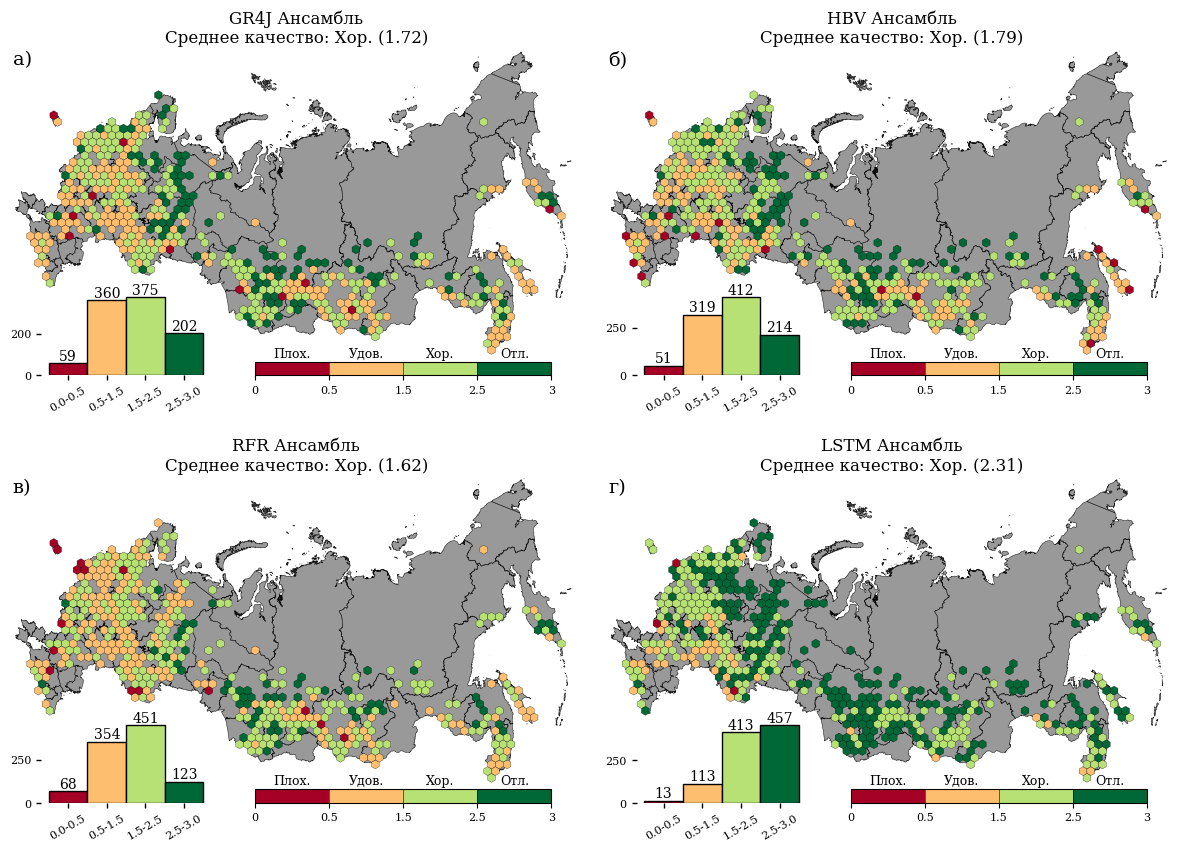

2026-04-07 01:49:01 | INFO     | PhDLogger | chapter_two | ℹ️  ✓ Composite quality hex maps saved: ../res_0426/chapter_two/figures/composite_quality_hex_maps_2x2.png
2026-04-07 01:49:01 | INFO     | PhDLogger | chapter_two | ℹ️    Hex radius: 66.0 km
2026-04-07 01:49:01 | INFO     | PhDLogger | chapter_two | ℹ️    Coverage statistics: 4 metrics processed


In [11]:
# ============================================================================
# VISUALIZATION 2: 2x2 Hex-Bin Grid - Composite Quality by Model Type
# ============================================================================

# Define discrete colormap (0-based scale: 0-3)
composite_colors = ["#d73027", "#fee08b", "#91cf60", "#1a9850"]  # Плох. -> Отл.
composite_boundaries = [0.0, 0.5, 1.5, 2.5, 3.0]
composite_labels = ["Плох.", "Удов.", "Хор.", "Отл."]

composite_cmap = mcolors.ListedColormap(composite_colors)
composite_norm = mcolors.BoundaryNorm(composite_boundaries, len(composite_colors))

# Define metric columns for plotting
metric_cols = [
    "Best_GR4J_Score",
    "Best_HBV_Score",
    "Best_RFR_Score",
    "Best_LSTM_Score",
]

# Calculate mean quality grade for each model type (for titles)
mean_scores = [ws_composite[col].mean() for col in metric_cols]


# Map numeric scores back to grades for display (0-based)
def score_to_grade(score):
    if score < 0.5:
        return "Плох."
    elif score < 1.5:
        return "Удов."
    elif score < 2.5:
        return "Хор."
    else:
        return "Отл."


mean_grades = [score_to_grade(score) for score in mean_scores]

# Create titles
title_texts = [
    f"GR4J Ансамбль\nСреднее качество: {mean_grades[0]} ({mean_scores[0]:.2f})",
    f"HBV Ансамбль\nСреднее качество: {mean_grades[1]} ({mean_scores[1]:.2f})",
    f"RFR Ансамбль\nСреднее качество: {mean_grades[2]} ({mean_scores[2]:.2f})",
    f"LSTM Ансамбль\nСреднее качество: {mean_grades[3]} ({mean_scores[3]:.2f})",
]

log.info("Generating 2x2 hex-bin map grid...")

# Generate hex-bin maps
fig, metric_hexes, r_km, coverage_stats = hexes_plots_n(
    watersheds=ws_composite,
    basemap_data=basemap_data,
    metric_cols=metric_cols,
    label_list=["а)", "б)", "в)", "г)"],
    nrows=2,
    ncols=2,
    target_ws_per_hex=6.0,
    quantile=0.5,
    area_weighted=False,
    min_overlap_share=0.15,
    list_of_limits=composite_boundaries,
    figsize=(15, 10),
    cmap_lims=(0.0, 3.0),
    basemap_alpha=0.8,
    annotate_counts=False,
    with_histogram=True,
    title_text=title_texts,
    cb_label=composite_labels,
)

output_path = f"{FIGURES_DIR}/composite_quality_hex_maps_2x2.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

log.info(f"✓ Composite quality hex maps saved: {output_path}")
log.info(f"  Hex radius: {r_km:.1f} km")
log.info(f"  Coverage statistics: {len(coverage_stats)} metrics processed")


In [12]:
# ============================================================================
# STEP 6: EXTRACT INDIVIDUAL METRIC GRADES FOR BEST MODEL
# ============================================================================

# For each gauge, extract NSE, PBIAS, R² from the best model/source combination
# and convert to quality grades

individual_metric_grades = {}

for gauge_id in composite_df.index:
    # Get best model/source combination for this gauge
    best_model_name = composite_df.loc[gauge_id, "Best_Model_Name"]

    if pd.isna(best_model_name):
        # No valid model for this gauge
        individual_metric_grades[gauge_id] = {
            "NSE_grade": 0,
            "PBIAS_grade": 0,
            "R2_grade": 0,
            "NSE_value": np.nan,
            "PBIAS_value": np.nan,
            "R2_value": np.nan,
        }
        continue

    # Parse model type and source from name (e.g., "GR4J (ERA5-Land)")
    # Best_Model_Name format: "MODEL_TYPE (SOURCE)"
    combo_name = best_model_name.replace(" (", "_").replace(")", "").replace(" ", "-")

    # Get the corresponding dataframe
    try:
        df = all_combinations[combo_name]

        # Extract metric values
        nse = df.loc[gauge_id, "NSE"]
        r2 = df.loc[gauge_id, "R2"]
        pbias = df.loc[gauge_id, "PBIAS"]

        # Convert to quality categories
        nse_category = get_quality_category(nse, "NSE")
        r2_category = get_quality_category(r2, "R2")
        pbias_category = get_quality_category(pbias, "PBIAS")

        # Encode to numeric grades (0-based)
        category_to_score = {"Плох.": 0, "Удов.": 1, "Хор.": 2, "Отл.": 3}

        individual_metric_grades[gauge_id] = {
            "NSE_grade": category_to_score[nse_category],
            "PBIAS_grade": category_to_score[pbias_category],
            "R2_grade": category_to_score[r2_category],
            "NSE_value": nse,
            "PBIAS_value": pbias,
            "R2_value": r2,
        }

    except KeyError as e:
        log.warning(f"Could not find data for gauge {gauge_id}, combo {combo_name}: {e}")
        individual_metric_grades[gauge_id] = {
            "NSE_grade": 0,
            "PBIAS_grade": 0,
            "R2_grade": 0,
            "NSE_value": np.nan,
            "PBIAS_value": np.nan,
            "R2_value": np.nan,
        }

# Convert to DataFrame
individual_metrics_df = pd.DataFrame.from_dict(individual_metric_grades, orient="index")

# Add to ws_composite for spatial visualization
for metric in ["NSE", "PBIAS", "R2"]:
    ws_composite[f"{metric}_Grade"] = (
        individual_metrics_df[f"{metric}_grade"].loc[ws_composite.index].fillna(0).values
    )
    ws_composite[f"{metric}_Value"] = (
        individual_metrics_df[f"{metric}_value"].loc[ws_composite.index].values
    )

log.info("✓ Individual metric grades calculated")

# Display summary
print("\n" + "=" * 80)
print("INDIVIDUAL METRIC QUALITY GRADES")
print("=" * 80)
print("\nDistribution by metric:")
for metric in ["NSE", "PBIAS", "R2"]:
    grade_col = f"{metric}_Grade"
    print(f"\n{metric}:")
    for grade_num, grade_label in enumerate(["Плох.", "Удов.", "Хор.", "Отл."]):
        count = (ws_composite[grade_col] == grade_num).sum()
        pct = (count / len(ws_composite)) * 100
        print(f"  {grade_label:12s}: {count:3d} ({pct:5.1f}%)")


2026-04-07 01:49:01 | INFO     | PhDLogger | chapter_two | ℹ️  ✓ Individual metric grades calculated



INDIVIDUAL METRIC QUALITY GRADES

Distribution by metric:

NSE:
  Плох.       :  47 (  4.7%)
  Удов.       : 155 ( 15.6%)
  Хор.        : 232 ( 23.3%)
  Отл.        : 562 ( 56.4%)

PBIAS:
  Плох.       :   6 (  0.6%)
  Удов.       :  81 (  8.1%)
  Хор.        :  94 (  9.4%)
  Отл.        : 815 ( 81.8%)

R2:
  Плох.       :  28 (  2.8%)
  Удов.       : 105 ( 10.5%)
  Хор.        : 438 ( 44.0%)
  Отл.        : 425 ( 42.7%)


2026-04-07 01:49:01 | INFO     | PhDLogger | chapter_two | ℹ️  Generating 2x2 combined quality maps (Overall + NSE + PBIAS + R²)...


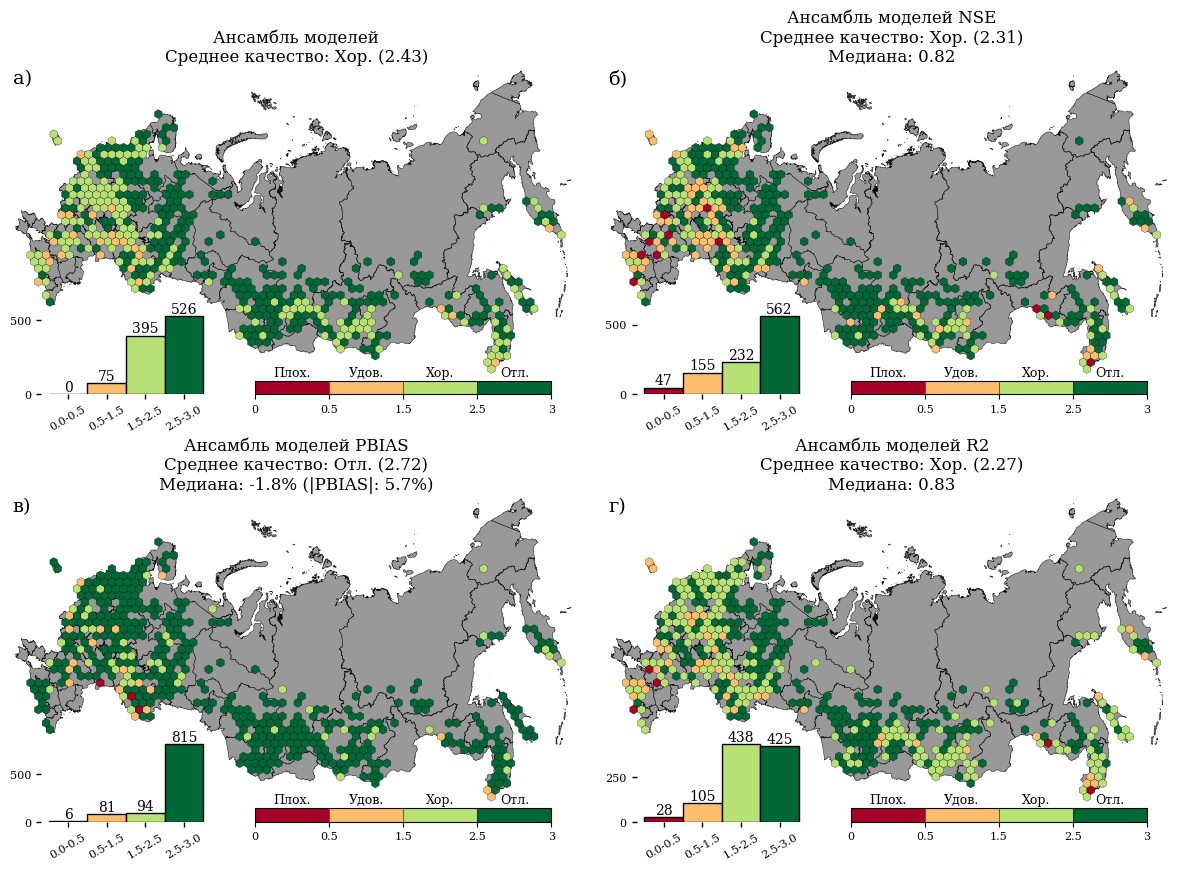

2026-04-07 01:49:08 | INFO     | PhDLogger | chapter_two | ℹ️  ✓ Combined quality hex maps saved: ../res_0426/chapter_two/figures/combined_quality_hex_maps_2x2.png
2026-04-07 01:49:08 | INFO     | PhDLogger | chapter_two | ℹ️    Hex radius: 66.0 km
2026-04-07 01:49:08 | INFO     | PhDLogger | chapter_two | ℹ️    Plots: Overall, NSE, PBIAS, R²


In [13]:
# ============================================================================
# VISUALIZATION 3 & 4 COMBINED: 2x2 Grid - Overall + Individual Metrics
# ============================================================================

# Prepare metric columns: Overall + NSE + PBIAS + R²
combined_metric_cols = ["Best_Overall_Score", "NSE_Grade", "PBIAS_Grade", "R2_Grade"]

# Calculate statistics for titles
overall_mean = ws_composite["Best_Overall_Score"].mean()
overall_grade = score_to_grade(overall_mean)

combined_titles = [
    f"Ансамбль моделей\nСреднее качество: {overall_grade} ({overall_mean:.2f})"
]

# Add individual metric titles
for metric in ["NSE", "PBIAS", "R2"]:
    grade_col = f"{metric}_Grade"
    mean_grade = ws_composite[grade_col].mean()
    grade_label = score_to_grade(mean_grade)

    value_col = f"{metric}_Value"

    if metric == "PBIAS":
        # Calculate both signed and absolute medians
        signed_median = ws_composite[value_col].median()
        abs_median = ws_composite[value_col].abs().median()
        combined_titles.append(
            f"Ансамбль моделей {metric}\nСреднее качество: {grade_label} ({mean_grade:.2f})\nМедиана: {signed_median:+.1f}% (|PBIAS|: {abs_median:.1f}%)"
        )
    else:
        median_value = ws_composite[value_col].median()
        combined_titles.append(
            f"Ансамбль моделей {metric}\nСреднее качество: {grade_label} ({mean_grade:.2f})\nМедиана: {median_value:.2f}"
        )

log.info("Generating 2x2 combined quality maps (Overall + NSE + PBIAS + R²)...")

# Generate 2x2 hex-bin map grid
fig, metric_hexes, r_km, coverage_stats = hexes_plots_n(
    watersheds=ws_composite,
    basemap_data=basemap_data,
    metric_cols=combined_metric_cols,
    label_list=["а)", "б)", "в)", "г)"],
    nrows=2,
    ncols=2,
    target_ws_per_hex=6.0,
    quantile=0.5,
    min_r_km=40.0,
    max_r_km=120.0,
    agg="median",
    min_overlap_share=0.15,
    area_weighted=False,
    list_of_limits=composite_boundaries,  # 0-based: [0.0, 0.5, 1.5, 2.5, 3.0]
    figsize=(15, 10),
    cmap_lims=(0.0, 3.0),
    basemap_alpha=0.8,
    annotate_counts=False,
    with_histogram=True,
    title_text=combined_titles,
    cb_label=composite_labels,  # ["Плох.", "Удов.", "Хор.", "Отл."]
)

output_path = f"{FIGURES_DIR}/combined_quality_hex_maps_2x2.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

log.info(f"✓ Combined quality hex maps saved: {output_path}")
log.info(f"  Hex radius: {r_km:.1f} km")
log.info("  Plots: Overall, NSE, PBIAS, R²")
